## Preparation

We first import related useful packages and specify the benchmark indices as well as the dates for extracting the stocks' data.

In [1]:
# pip install python-dateutil
import yfinance as yf
import pandas as pd
import numpy as np
from datetime import datetime
from dateutil.relativedelta import relativedelta
import requests
import plotly.express as px
import plotly as py
import plotly.io as pio
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from plotly.offline import download_plotlyjs, init_notebook_mode, plot, iplot

In [91]:
DJIA = "^DJI"
NADQ = "^IXIC"

end_date_3y = datetime.now().date() # use the current date as the end date
start_date_3y = end_date_3y - relativedelta(years = 3)

## Filtering and Analysis

To identify the companies that exhibit a high correlation (correlation coefficient greater than 0.7), we need to obtain the data for the 2 indices and their components respectively. 

Using Slickcharts, we can get the current list of the components of the benchmark indices. Then we can get the prices of the stocks and create a data frame composed of the components as well as the index to calculate the correlation coefficient.

In [3]:
def get_historical_data(ticker, start_date, end_date):
    historical_data = yf.download(ticker, start = start_date, end = end_date)
    return historical_data

DJIA_data = get_historical_data(DJIA, start_date_3y, end_date_3y)
DJIA_data

NADQ_data = get_historical_data(NADQ, start_date_3y, end_date_3y)
NADQ_data

[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed


,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2020-12-29,12965.389648,12973.330078,12821.959961,12850.219727,12850.219727,4726920000
2020-12-30,12906.509766,12924.929688,12857.759766,12870.000000,12870.000000,5343010000
2020-12-31,12877.089844,12902.070312,12821.230469,12888.280273,12888.280273,4815840000
2021-01-04,12958.519531,12958.719727,12543.240234,12698.450195,12698.450195,6636170000
2021-01-05,12665.650391,12828.269531,12665.650391,12818.959961,12818.959961,6971860000
...,...,...,...,...,...,...
2023-12-21,14923.139648,14970.809570,14837.469727,14963.870117,14963.870117,5465640000
2023-12-22,15006.179688,15047.190430,14927.120117,14992.969727,14992.969727,4796600000
2023-12-26,15028.690430,15101.179688,15024.059570,15074.570312,15074.570312,6120600000


In [4]:
# Only keep the column for closing prices
def get_close(index_df):
    index_close = index_df.loc[:,"Close"]
    return index_close

DJIA_close = get_close(DJIA_data)
DJIA_close

NADQ_close = get_close(NADQ_data)
NADQ_close

Date
2020-12-29    12850.219727
2020-12-30    12870.000000
2020-12-31    12888.280273
2021-01-04    12698.450195
2021-01-05    12818.959961
                  ...     
2023-12-21    14963.870117
2023-12-22    14992.969727
2023-12-26    15074.570312
2023-12-27    15099.179688
2023-12-28    15095.139648
Name: Close, Length: 755, dtype: float64

In [5]:
# Obtain the full list of the 2 indices
def list_slickcharts(url) -> pd.DataFrame:
    user_agent = 'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/605.1.15 (KHTML, like Gecko) Version/16.6 Safari/605.1.15'
    response = requests.get(url, headers = {'User-Agent': user_agent})
    index_slickcharts = pd.read_html(response.text, match = 'Symbol', index_col = 'Symbol')[0]
    return index_slickcharts

DJIA_slickcharts = list_slickcharts('https://www.slickcharts.com/dowjones')
DJIA_slickcharts

Nasdaq100_slickcharts = list_slickcharts('https://www.slickcharts.com/nasdaq100')
Nasdaq100_slickcharts

,#,Company,Weight,Price,Chg,% Chg
Symbol,,,,,,
AAPL,1,Apple Inc,9.206,193.85,0.27,(0.14%)
MSFT,2,Microsoft Corp,8.520,375.95,0.67,(0.18%)
AMZN,3,Amazon.com Inc,4.856,153.28,-0.11,(-0.07%)
AVGO,4,Broadcom Inc,4.164,1122.25,-0.16,(-0.01%)
META,5,Meta Platforms Inc,3.872,358.34,0.02,(0.00%)
...,...,...,...,...,...,...
TTWO,97,Take-Two Interactive Software Inc,0.217,0.00,0.00,(0.00%)
SPLK,98,Splunk Inc,0.203,0.00,0.00,(0.00%)
WBA,99,Walgreens Boots Alliance Inc,0.182,26.58,-0.03,(-0.09%)


In [6]:
# Get the historical data of the components of the index
def get_comp_data(index_slickcharts, start_date, end_date):
    index_comp = list(index_slickcharts.index)
    index_comp_data = get_historical_data(index_comp, start_date, end_date)
    return index_comp_data

DJIA_comp_data = get_comp_data(DJIA_slickcharts, start_date_3y, end_date_3y)
DJIA_comp_data

NADQ_comp_data = get_comp_data(Nasdaq100_slickcharts, start_date_3y, end_date_3y)
NADQ_comp_data

[*********************100%%**********************]  30 of 30 completed
[*********************100%%**********************]  101 of 101 completed


Adj Close                                                  \
                  AAPL        ABNB        ADBE         ADI         ADP   
Date                                                                     
2020-12-29  132.529373  150.000000  502.109985  136.087158  164.662186   
2020-12-30  131.399368  148.429993  497.450012  138.474289  163.664062   
2020-12-31  130.387238  146.800003  500.119995  139.942612  165.914520   
2021-01-04  127.164146  139.149994  485.339996  138.322754  159.097153   
2021-01-05  128.736404  148.300003  485.690002  140.795166  158.654587   
...                ...         ...         ...         ...         ...   
2023-12-21  194.679993  142.089996  600.140015  196.279999  228.990005   
2023-12-22  193.600006  140.800003  598.750000  197.100006  230.970001   
2023-12-26  193.050003  138.720001  598.260010  198.869995  232.539993   
2023-12-27  193.149994  136.550003  596.080017  199.350006  231.610001   
2023-12-28  193.580002  137.000000  595.520020  200.240005  232.490005   

                                                                       ...  \
                  ADSK        AEP        AMAT         AMD        AMGN  ...   
Date                                                                   ...   
2020-12-29  298.109985  72.803612   82.145065   90.620003  206.177963  ...   
2020-12-30  299.410004  73.099548   84.786736   92.290001  206.450592  ...   
2020-12-31  305.339996  74.677925   84.123856   91.709999  208.949799  ...   
2021-01-04  296.839996  73.126450   84.679497   92.300003  205.987122  ...   
2021-01-05  301.700012  73.027802   87.340652   92.769997  206.986786  ...   
...                ...        ...         ...         ...         ...  ...   
2023-12-21  241.889999  80.040001  161.389999  139.910004  279.329987  ...   
2023-12-22  242.759995  80.379997  162.050003  139.600006  284.160004  ...   
2023-12-26  245.070007  80.730003  164.279999  143.410004  283.899994  ...   
2023-12-27  245.110001  80.809998  164.210007  146.070007  286.529999  ...   
2023-12-28  244.910004  81.330002  163.119995  148.759995  288.459991  ...   

              Volume                                                         \
                 TTD     TTWO      TXN    VRSK     VRTX       WBA       WBD   
Date                                                                          
2020-12-29  15876000   879200  2433700  415800   656600   4004400   4271800   
2020-12-30  13649000  1524100  2213800  339900   819100   4194300   3191200   
2020-12-31   7900000   643900  2906200  358200  1161100   7696000   5191500   
2021-01-04  12177000  1849900  4659900  733400  2117700   9101800   7537100   
2021-01-05   8202000   878000  4734100  622300  1730500   7431000  10031500   
...              ...      ...      ...     ...      ...       ...       ...   
2023-12-21   2266100  1069300  4040100  646300   819100  10668500  46101300   
2023-12-22   7138800  1347200  3492400  918800   804200   9776300  21124400   
2023-12-26   3697200   763300  3202200  516500   531600  10181100  17934500   
2023-12-27   2541100   936900  3264900  534400   594000   8265500  20714200   
2023-12-28   2570600   784900  3023000  374300   735600   7897700  16574000   

                                       
               WDAY      XEL       ZS  
Date                                   
2020-12-29  1407900  1761400  2225500  
2020-12-30  1140400  1296400  1126400  
2020-12-31  1329600  1743300  1469600  
2021-01-04  3332800  3197100  3510700  
2021-01-05  2773800  1976800  2365500  
...             ...      ...      ...  
2023-12-21  1201300  2807700  1250500  
2023-12-22  1178100  2429300   912600  
2023-12-26   798200  2147500   770000  
2023-12-27   759200  2865900   840800  
2023-12-28   839300  2421900   575000  

[755 rows x 606 columns]

In [7]:
# Only keep the closing prices for each stock
DJIA_comp_close = get_close(DJIA_comp_data)
DJIA_comp_close

NADQ_comp_close = get_close(NADQ_comp_data)
NADQ_comp_close

,AAPL,ABNB,ADBE,ADI,ADP,ADSK,AEP,AMAT,AMD,AMGN,...,TTD,TTWO,TXN,VRSK,VRTX,WBA,WBD,WDAY,XEL,ZS
Date,,,,,,,,,,,,,,,,,,,,,
2020-12-29,134.869995,150.000000,502.109985,143.660004,174.869995,298.109985,81.180000,84.269997,90.620003,226.869995,...,82.028999,202.449997,161.179993,205.669998,233.490005,39.410000,29.690001,237.720001,65.419998,197.839996
2020-12-30,133.720001,148.429993,497.450012,146.179993,173.809998,299.410004,81.510002,86.980003,92.290001,227.169998,...,81.800003,206.350006,162.699997,205.779999,232.679993,39.340000,29.809999,236.929993,65.650002,201.309998
2020-12-31,132.690002,146.800003,500.119995,147.729996,176.199997,305.339996,83.269997,86.300003,91.709999,229.919998,...,80.099998,207.789993,164.130005,207.589996,236.339996,39.880001,30.090000,239.610001,66.669998,199.710007
2021-01-04,129.410004,139.149994,485.339996,146.020004,168.960007,296.839996,81.540001,86.870003,92.300003,226.660004,...,77.343002,201.850006,162.220001,202.880005,229.429993,41.400002,30.629999,228.080002,65.660004,196.089996
2021-01-05,131.009995,148.300003,485.690002,148.630005,168.490005,301.700012,81.430000,89.599998,92.769997,227.759995,...,78.853996,204.740005,163.410004,201.970001,228.580002,41.160000,31.520000,225.360001,65.019997,193.479996
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-12-21,194.679993,142.089996,600.140015,196.279999,228.990005,241.889999,80.040001,161.389999,139.910004,279.329987,...,76.379997,160.389999,166.809998,235.009995,400.630005,26.059999,11.490000,272.899994,61.529999,221.330002
2023-12-22,193.600006,140.800003,598.750000,197.100006,230.970001,242.759995,80.379997,162.050003,139.600006,284.160004,...,73.430000,161.949997,168.240005,236.199997,405.250000,26.219999,11.270000,272.570007,62.060001,221.679993
2023-12-26,193.050003,138.720001,598.260010,198.869995,232.539993,245.070007,80.730003,164.279999,143.410004,283.899994,...,73.589996,161.619995,170.809998,237.029999,407.660004,26.610001,11.500000,273.970001,62.250000,224.589996


In [8]:
# Merge the index data with the components' data
def get_merged_df(index, index_df, comp_df):
    merged_df = pd.concat([index_df, comp_df], axis = 1)
    merged_df.rename(columns = {"Close": index}, inplace = True)
    return merged_df

merged_DJIA = get_merged_df(DJIA, DJIA_close, DJIA_comp_close)
merged_DJIA

merged_NADQ = get_merged_df(NADQ, NADQ_close, NADQ_comp_close)
merged_NADQ

,^IXIC,AAPL,ABNB,ADBE,ADI,ADP,ADSK,AEP,AMAT,AMD,...,TTD,TTWO,TXN,VRSK,VRTX,WBA,WBD,WDAY,XEL,ZS
Date,,,,,,,,,,,,,,,,,,,,,
2020-12-29,12850.219727,134.869995,150.000000,502.109985,143.660004,174.869995,298.109985,81.180000,84.269997,90.620003,...,82.028999,202.449997,161.179993,205.669998,233.490005,39.410000,29.690001,237.720001,65.419998,197.839996
2020-12-30,12870.000000,133.720001,148.429993,497.450012,146.179993,173.809998,299.410004,81.510002,86.980003,92.290001,...,81.800003,206.350006,162.699997,205.779999,232.679993,39.340000,29.809999,236.929993,65.650002,201.309998
2020-12-31,12888.280273,132.690002,146.800003,500.119995,147.729996,176.199997,305.339996,83.269997,86.300003,91.709999,...,80.099998,207.789993,164.130005,207.589996,236.339996,39.880001,30.090000,239.610001,66.669998,199.710007
2021-01-04,12698.450195,129.410004,139.149994,485.339996,146.020004,168.960007,296.839996,81.540001,86.870003,92.300003,...,77.343002,201.850006,162.220001,202.880005,229.429993,41.400002,30.629999,228.080002,65.660004,196.089996
2021-01-05,12818.959961,131.009995,148.300003,485.690002,148.630005,168.490005,301.700012,81.430000,89.599998,92.769997,...,78.853996,204.740005,163.410004,201.970001,228.580002,41.160000,31.520000,225.360001,65.019997,193.479996
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-12-21,14963.870117,194.679993,142.089996,600.140015,196.279999,228.990005,241.889999,80.040001,161.389999,139.910004,...,76.379997,160.389999,166.809998,235.009995,400.630005,26.059999,11.490000,272.899994,61.529999,221.330002
2023-12-22,14992.969727,193.600006,140.800003,598.750000,197.100006,230.970001,242.759995,80.379997,162.050003,139.600006,...,73.430000,161.949997,168.240005,236.199997,405.250000,26.219999,11.270000,272.570007,62.060001,221.679993
2023-12-26,15074.570312,193.050003,138.720001,598.260010,198.869995,232.539993,245.070007,80.730003,164.279999,143.410004,...,73.589996,161.619995,170.809998,237.029999,407.660004,26.610001,11.500000,273.970001,62.250000,224.589996


In [9]:
# Identify the companies with high correlation coefficients to their respective index
def companies_high_corr(index, index_merged_df, corr_coef_spec):
    corr_coef = index_merged_df.corrwith(index_merged_df[index])
    high_corr_com = corr_coef[corr_coef > 0.7]
    return high_corr_com

DJIA_high_corr_comp = companies_high_corr(DJIA, merged_DJIA, 0.7)
DJIA_high_corr_comp

^DJI    1.000000
AXP     0.713389
CSCO    0.783646
GS      0.750952
HD      0.778593
JPM     0.785465
dtype: float64

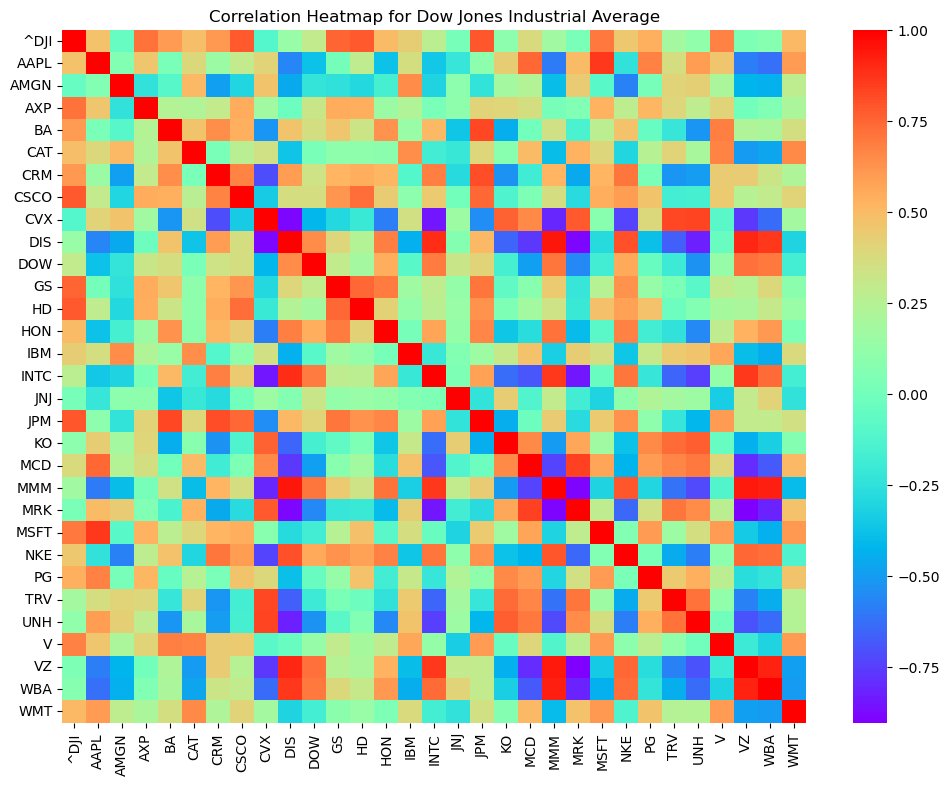

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_matrix = merged_DJIA.corr()
plt.figure(figsize = (12, 9))
sns.heatmap(correlation_matrix, annot = False, cmap = 'rainbow')
plt.title('Correlation Heatmap for Dow Jones Industrial Average')
plt.show()

In [11]:
NADQ_high_corr_comp = companies_high_corr(NADQ, merged_NADQ, 0.7)
NADQ_high_corr_comp
#len(NADQ_high_corr_comp)

^IXIC    1.000000
ABNB     0.760601
ADBE     0.932719
ADSK     0.714951
AMAT     0.830374
AMD      0.772654
AMZN     0.882945
ANSS     0.863346
ASML     0.796772
CHTR     0.700726
CMCSA    0.786466
CRWD     0.764616
CSCO     0.785945
DASH     0.784868
DDOG     0.751802
GOOG     0.835587
GOOGL    0.830094
IDXX     0.835781
INTU     0.808876
ISRG     0.824540
LRCX     0.821871
MDB      0.903048
META     0.902323
MRVL     0.778398
MU       0.735195
NFLX     0.848796
NXPI     0.865252
SPLK     0.729197
TEAM     0.751168
TTD      0.821342
TTWO     0.769289
WDAY     0.920538
ZS       0.812373
dtype: float64

## Conclusion

According to the results shown above, there are 5 companies and 33 companies that exhibit a high correlation with the Dow Jones Industrial Average and Nasdaq-100 respectively. 

Cisco Systems Inc. has the highest correlation coefficient (0.79) with the Dow Jones Industrial Average, and Adobe Inc. has the highest correlation coefficient (0.93) with the Nasdaq-100.

In [103]:
DJIA_slickcharts

,#,Company,Weight,Price,Chg,% Chg
Symbol,,,,,,
UNH,1,Unitedhealth Group Inc,9.173275,526.40,1.50,(0.29%)
GS,2,Goldman Sachs Group Inc,6.752991,386.48,0.07,(0.02%)
MSFT,3,Microsoft Corp,6.558481,375.95,0.67,(0.18%)
HD,4,Home Depot Inc,6.070544,347.94,0.58,(0.17%)
CAT,5,Caterpillar Inc,5.188344,297.88,1.00,(0.34%)
MCD,6,Mcdonald S Corp,5.170169,295.43,-0.41,(-0.14%)
AMGN,7,Amgen Inc,5.041194,287.22,-1.24,(-0.43%)
CRM,8,Salesforce Inc,4.641338,265.51,-0.07,(-0.03%)
V,9,Visa Inc Class A Shares,4.550811,259.28,-1.12,(-0.43%)


In [88]:
DJIA_slickcharts.index

Index(['UNH', 'GS', 'MSFT', 'HD', 'CAT', 'MCD', 'AMGN', 'CRM', 'V', 'BA',
       'HON', 'AAPL', 'TRV', 'AXP', 'JPM', 'IBM', 'WMT', 'JNJ', 'CVX', 'PG',
       'MMM', 'NKE', 'MRK', 'DIS', 'KO', 'DOW', 'CSCO', 'INTC', 'VZ', 'WBA'],
      dtype='object', name='Symbol')

In [ ]:
import concurrent
from concurrent.futures import ThreadPoolExecutor

# Function to get data and calculate correlation
def process_stock(stock_symbol):
    try:
        stock_data = get_historical_data(stock_symbol, start_date_3y, end_date_3y)
        stock_close = stock_data['Close']
        correlation = stock_close.corr(DJIA_close)
        return stock_symbol, correlation
    except KeyError as e:
        print(f"Error processing {stock_symbol}: {e}")
        return stock_symbol, None

# Using ThreadPoolExecutor to process stocks in parallel
with ThreadPoolExecutor(max_workers=5) as executor:
    # Submit tasks to the executor
    futures = [executor.submit(process_stock, Symbol) for Symbol in DJIA_slickcharts.index]

    # Collect results as they complete
    for future in concurrent.futures.as_completed(futures):
        symbol, correlation = future.result()
        if correlation is not None and correlation > 0.7:
            print(f"{symbol} has a high correlation of {correlation}")


In [ ]:
import concurrent
from concurrent.futures import ThreadPoolExecutor

# Function to get data and calculate correlation
def process_stock(stock_symbol):
    stock_data = get_historical_data(stock_symbol, start_date_3y, end_date_3y)
    stock_close = stock_data['Close']
    correlation = stock_close.corr(DJIA_close)
    return (stock_symbol, correlation)

# Using ThreadPoolExecutor to process stocks in parallel
with ThreadPoolExecutor(max_workers = 5) as executor:
    # Submit tasks to the executor
    futures = [executor.submit(process_stock, Symbol) for Symbol in DJIA_slickcharts.index]

    # Collect results as they complete
    for future in concurrent.futures.as_completed(futures):
        symbol, correlation = future.result()
        if correlation > 0.7:
            print(f"{symbol} has a high correlation of {correlation}")